<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_23_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import keras
from keras import layers

In [5]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [9]:
#Veriyi Çağırma ve Tanıma

digits = load_digits()

X = digits.images
y = digits.target

In [13]:
print("X Şekli:", X.shape)
print("y Şekli:", y.shape)
#

X Şekli: (1797, 8, 8)
y Şekli: (1797,)


In [15]:
print("Sınıflar:",np.unique(y))

Sınıflar: [0 1 2 3 4 5 6 7 8 9]


In [17]:
#bir resim aslında ne demek?
print(X[0])

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


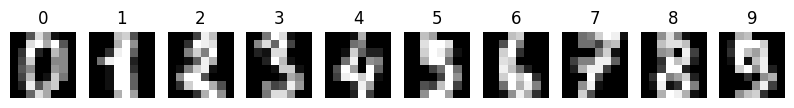

In [19]:
#İLK 10 Resmi Çizdir

plt.figure(figsize=(10,10))
for i in range(10):
    plt.subplot(1,10,i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.title(y[i])
    plt.axis("off")

plt.show()
#

In [21]:
#Sınıflar Dengeli mi?

print("Her rakamdan kaç resim var?")
print(np.bincount(y)) #her sayının kaç adet geçtiği

Her rakamdan kaç resim var?
[178 182 177 183 181 182 181 179 174 180]


In [23]:
#VERİYİ HAZIRLAMA - Ölçekleme - train ve test olarak ayırabiliriz.

#ÖLÇEKLEME
print("En küçük değer:", X.min())
print("En büyük değer:", X.max())

X = X / 16.0

En küçük değer: 0.0
En büyük değer: 16.0


In [25]:
print("Yeni en büyük değer ölçekleme sonrası:", X.max()) # Verimiz sıfır ile 1 arasına ölçeklenmiş oldu.

Yeni en büyük değer ölçekleme sonrası: 1.0


In [26]:
# KANAL BOYUTU EKLEME

X = X.reshape(-1, 8, 8, 1) # CNN mimarisinde kanal boyutu eklenmesi gerekiyor. Sayıların anlamı sırası ile -1 noyutu sne hesapla 1797 adet var ona bakacak. 8, 8 boyut, 1 de gri olduğu için tek kanal. renkli olsa 3 kanal olacaktı.
print("Yeni Şekil:", X.shape)

Yeni Şekil: (1797, 8, 8, 1)


In [28]:
# Train ve Test olarak ayırma

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Eğitim:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
#

Eğitim: (1437, 8, 8, 1) (1437,)
Test: (360, 8, 8, 1) (360,)


In [29]:
#MODELİ KURMA (CNN Mimarisi)

model = keras.Sequential([
    keras.Input(shape=(8, 8, 1)), # Modele girecek resmin şekli
    layers.Conv2D(8, (3, 3), activation="relu"), # Evrişim katmanı
    layers.MaxPooling2D((2, 2)), # her 2*2 bölgeden en büyük değeri al. Boyutu yarıya indir.
    layers.Flatten(), # tabloyu tek satıra diz.
    layers.Dense(10, activation="softmax") # 10 rakamın olasılığını üret.

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 6, 6, 8)        │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 72)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           730 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 810 (3.16 KB)

 Trainable params: 810 (3.16 KB)

 Non-trainable params: 0 (0.00 B)